In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
from google.colab import drive
drive.mount('/content/drive')

RAIZ_TILES = Path("/content/drive/MyDrive/IA/tiles_128/proporcional_filas6_max40")
METADATA = RAIZ_TILES / "tiles_metadata.csv"
TILES_NPY = RAIZ_TILES / "tiles.npy"
VOCABULARIO = RAIZ_TILES / "vocabulario_kmeans.joblib"
HISTOGRAMAS = RAIZ_TILES / "histogramas_tiles.csv"
MODELO_FINAL = RAIZ_TILES / "modelo_logistico.joblib"
ETIQUETAS_MANUALES = RAIZ_TILES / "etiquetas_manual.csv"

TILE = 128
PARCHE = 32
N_PARCHES = (TILE // PARCHE) ** 2   # 16
K_VOCABULARIO = 50
K_TILES = 5
SEMILLA = 42

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
meta = pd.read_csv(METADATA)
print(meta.shape)
print(meta.columns.tolist())
print(meta["autor"].value_counts())

(17880, 10)
['tile_archivo', 'autor', 'foto_original', 'foto_id', 'tile_k', 'columna', 'fila', 'lado_original_px', 'ancho_foto', 'alto_foto']
autor
maria_luciana_salinas_vilar           7240
carlos_walter_pacheco_lora            3360
Franky_Quispe_Zarate                  3000
erick_alexander_ochoa_paz             1200
laura_luciana_diaz_campos             1080
jose_manuel_gallardo_laura             560
alvaro_david_arancibia_estrada         400
luis_fernando_quispe_sullca            400
camila_fernanda_montecinos_solis       320
pedro_jhoel_antonio_magne_ordoñez     320
Name: count, dtype: int64


In [4]:
import pandas as pd
from pathlib import Path

METADATA = Path("/content/drive/MyDrive/IA/tiles_128/proporcional_filas6_max40/tiles_metadata.csv")
meta = pd.read_csv(METADATA)
print("Columnas:", list(meta.columns))
print("Shape:", meta.shape)
print(meta.head())

Columnas: ['tile_archivo', 'autor', 'foto_original', 'foto_id', 'tile_k', 'columna', 'fila', 'lado_original_px', 'ancho_foto', 'alto_foto']
Shape: (17880, 10)
                          tile_archivo                 autor  \
0  Franky_Quispe_Zarate/img001_000.png  Franky_Quispe_Zarate   
1  Franky_Quispe_Zarate/img001_001.png  Franky_Quispe_Zarate   
2  Franky_Quispe_Zarate/img001_002.png  Franky_Quispe_Zarate   
3  Franky_Quispe_Zarate/img001_003.png  Franky_Quispe_Zarate   
4  Franky_Quispe_Zarate/img001_004.png  Franky_Quispe_Zarate   

                                       foto_original foto_id  tile_k  columna  \
0  Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...  img001       0        1   
1  Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...  img001       1        2   
2  Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...  img001       2        3   
3  Franky_Quispe_Zarate/271c1353-391f-4516-a609-0...  img001       3        4   
4  Franky_Quispe_Zarate/271c1353-391f-4516-a609-0..

In [7]:
if TILES_NPY.exists():
    tiles = np.load(TILES_NPY)
else:
    from PIL import Image
    rutas = [RAIZ_TILES / row["tile_archivo"] for _, row in meta.iterrows()]
    tiles = np.empty((len(rutas), TILE, TILE, 3), dtype=np.uint8)
    for i, r in enumerate(rutas):
        tiles[i] = np.array(Image.open(r).convert("RGB"))
    np.save(TILES_NPY, tiles)
print("Tiles:", tiles.shape)

KeyboardInterrupt: 

In [8]:
from pathlib import Path
RAIZ_TILES = Path("/content/drive/MyDrive/IA/tiles_128/proporcional_filas6_max40")
pngs = list(RAIZ_TILES.rglob("*.png"))
print("PNGs encontrados:", len(pngs))
print(pngs[:3])

PNGs encontrados: 17880
[PosixPath('/content/drive/MyDrive/IA/tiles_128/proporcional_filas6_max40/Franky_Quispe_Zarate/img051_000.png'), PosixPath('/content/drive/MyDrive/IA/tiles_128/proporcional_filas6_max40/Franky_Quispe_Zarate/img051_001.png'), PosixPath('/content/drive/MyDrive/IA/tiles_128/proporcional_filas6_max40/Franky_Quispe_Zarate/img051_002.png')]


In [9]:
import shutil
from pathlib import Path

LOCAL = Path("/content/tiles_local")
if LOCAL.exists():
    shutil.rmtree(LOCAL)
shutil.copytree(RAIZ_TILES, LOCAL)
print("Copiado a local:", len(list(LOCAL.rglob("*.png"))), "PNGs")

Copiado a local: 17880 PNGs


In [10]:
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
import numpy as np

if TILES_NPY.exists():
    tiles = np.load(TILES_NPY)
    print("Cargado desde .npy:", tiles.shape)
else:
    rutas = [LOCAL / row["tile_archivo"] for _, row in meta.iterrows()]
    print("Total a leer:", len(rutas))

    def leer(r):
        return np.array(Image.open(r).convert("RGB"))

    tiles = np.empty((len(rutas), TILE, TILE, 3), dtype=np.uint8)
    with ThreadPoolExecutor(max_workers=8) as ex:
        for i, arr in enumerate(ex.map(leer, rutas)):
            tiles[i] = arr
            if (i + 1) % 2000 == 0:
                print(f"{i+1}/{len(rutas)}")
    np.save(TILES_NPY, tiles)
    print("Guardado:", tiles.shape)

Total a leer: 17880
2000/17880
4000/17880
6000/17880
8000/17880
10000/17880
12000/17880
14000/17880
16000/17880
Guardado: (17880, 128, 128, 3)


In [11]:
autores = meta["autor"].unique()
rng = np.random.default_rng(SEMILLA)
rng.shuffle(autores)
n_train = int(0.7 * len(autores))
autores_train = set(autores[:n_train])
autores_test = set(autores[n_train:])
meta["split"] = meta["autor"].apply(lambda a: "train" if a in autores_train else "test")
assert not (autores_train & autores_test)
print(meta["split"].value_counts())

split
train    9920
test     7960
Name: count, dtype: int64


In [13]:
def parches_de_tile(tile):
    p = []
    for i in range(0, TILE, PARCHE):
        for j in range(0, TILE, PARCHE):
            p.append(tile[i:i+PARCHE, j:j+PARCHE])
    return np.stack(p)

In [14]:
from sklearn.cluster import MiniBatchKMeans

mask_train = meta["split"].values == "train"
parches_train = np.stack([parches_de_tile(t) for t in tiles[mask_train][:20000]])
parches_train = parches_train.reshape(-1, PARCHE*PARCHE*3).astype(np.float32) / 255.0

if VOCABULARIO.exists():
    vocab = joblib.load(VOCABULARIO)
else:
    vocab = MiniBatchKMeans(n_clusters=K_VOCABULARIO, random_state=SEMILLA, batch_size=1024)
    vocab.fit(parches_train)
    joblib.dump(vocab, VOCABULARIO)
print("Vocabulario:", vocab.cluster_centers_.shape)

Vocabulario: (50, 3072)


In [15]:
def histograma_tile(tile):
    p = parches_de_tile(tile).reshape(N_PARCHES, -1).astype(np.float32) / 255.0
    etiquetas = vocab.predict(p)
    return np.bincount(etiquetas, minlength=K_VOCABULARIO) / N_PARCHES

hist = np.stack([histograma_tile(t) for t in tiles])
df_hist = pd.concat([meta.reset_index(drop=True),
                     pd.DataFrame(hist, columns=[f"c{i}" for i in range(K_VOCABULARIO)])], axis=1)
df_hist.to_csv(HISTOGRAMAS, index=False)
print(df_hist.shape)

(17880, 61)


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in [3, 4, 5, 6, 7]:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEMILLA)
    lab = km.fit_predict(hist)
    print(k, silhouette_score(hist, lab))

3 0.10330816312203335
4 0.11399765320793794
5 0.12771259301706345
6 0.13010069392112444
7 0.12335250846736266


In [17]:
km_tiles = KMeans(n_clusters=K_TILES, init="k-means++", n_init=10, random_state=SEMILLA)
df_hist["cluster_tile"] = km_tiles.fit_predict(hist)
joblib.dump(km_tiles, MODELO_FINAL)
print(df_hist["cluster_tile"].value_counts())

cluster_tile
0    8730
1    3382
3    2520
2    2287
4     961
Name: count, dtype: int64


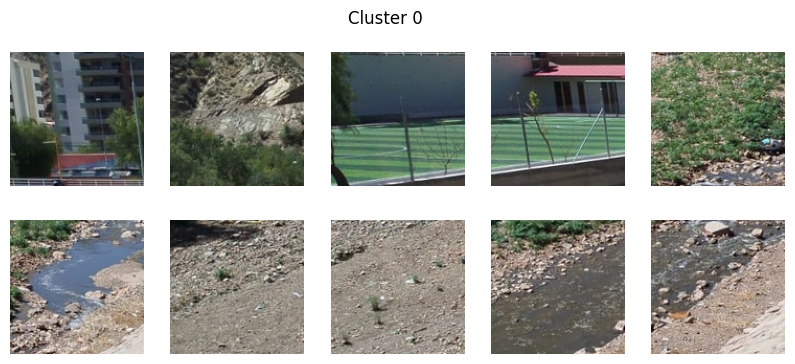

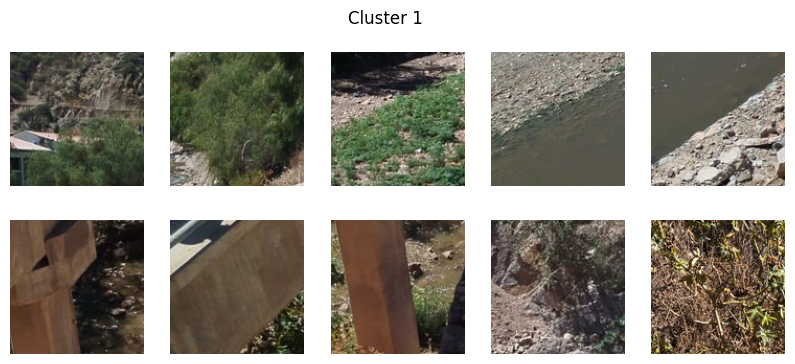

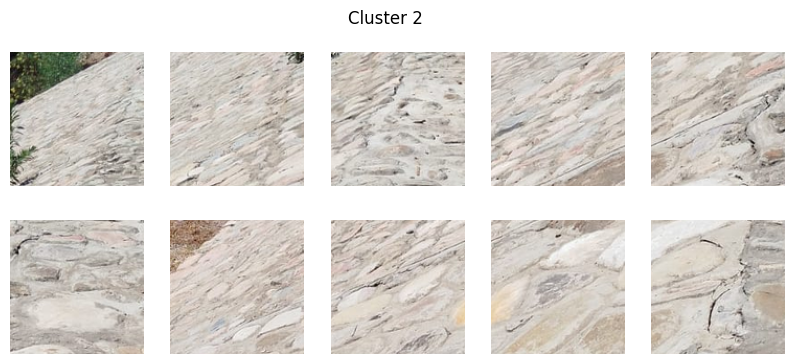

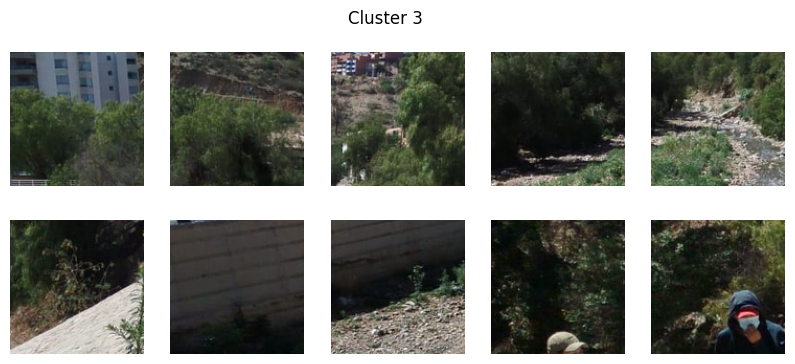

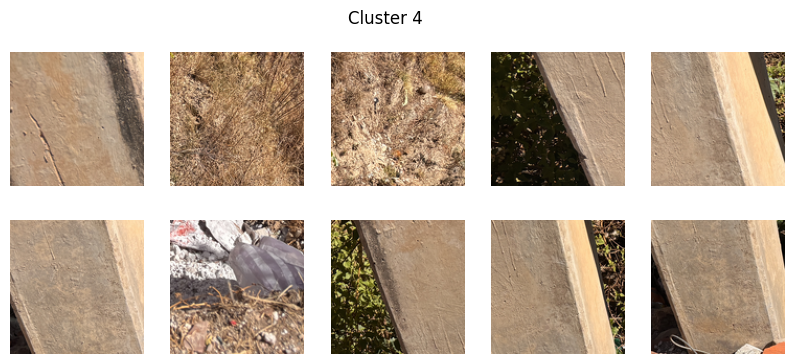

In [18]:
import matplotlib.pyplot as plt

for c in range(K_TILES):
    idx = np.where(df_hist["cluster_tile"] == c)[0][:10]
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(tiles[i]); ax.axis("off")
    fig.suptitle(f"Cluster {c}")
    plt.show()

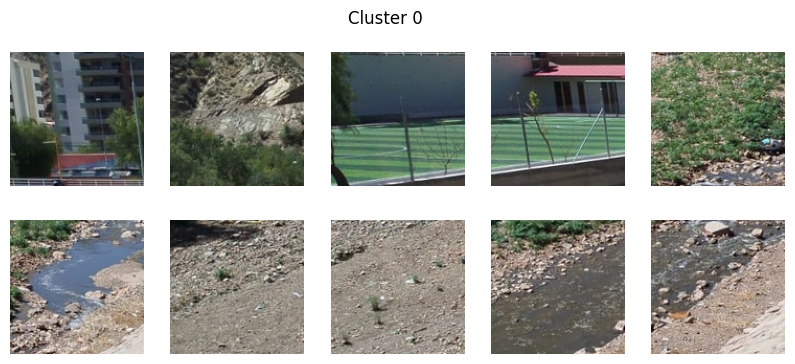

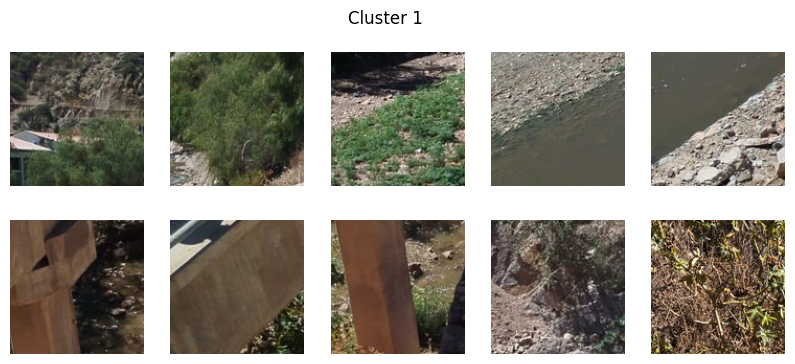

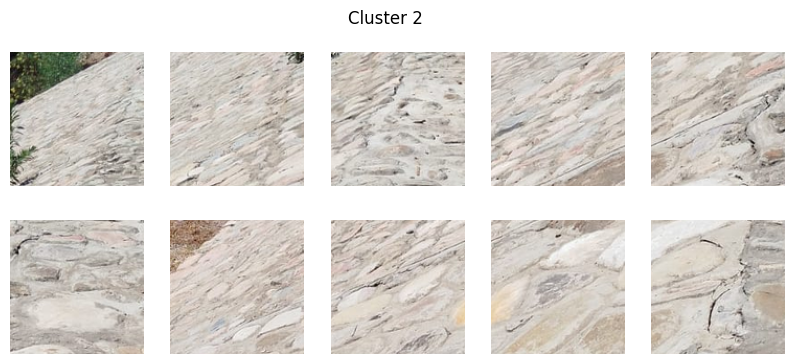

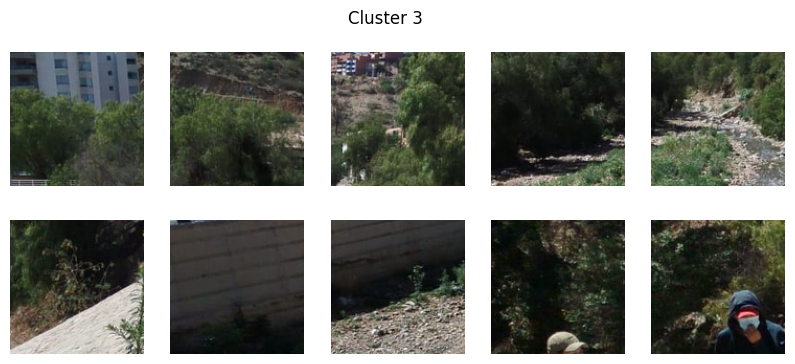

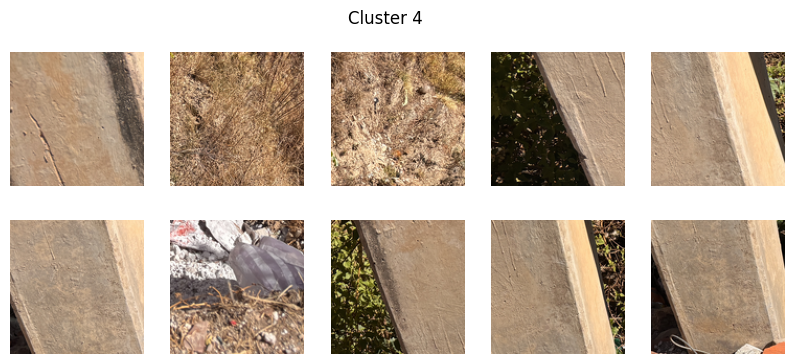

In [19]:
import matplotlib.pyplot as plt

for c in range(K_TILES):
    idx = np.where(df_hist["cluster_tile"] == c)[0][:10]
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(tiles[i]); ax.axis("off")
    fig.suptitle(f"Cluster {c}")
    plt.show()